# Auditoría de ES ponderado

Pregunta: ¿las convenciones de cola calculan la misma medida sobre pérdidas discretas? Hipótesis: la integración de masa fraccionaria coincide con el LP a tolerancia 1e-8. La fórmula es conocida (Acerbi–Tasche; Rockafellar–Uryasev), no un estimador nuevo.

Convención: pérdidas positivas, confianza 0.975, escenarios finitos; pesos conocidos. Resultados numéricos, no backtesting fuera de muestra.

In [1]:
import sys, json, csv
from pathlib import Path
from src.tail import weighted_tail
from src.oracle import lp_es
print('Python:', sys.version.split()[0])
x = [0.] * 99 + [100.]
print('ES exacto:', weighted_tail(x).es)
print('LP:', lp_es(x))
print('Escenarios ponderados:', weighted_tail([0,100], weights=[99,1]))

Python: 3.12.14
ES exacto: 39.999999999999964
LP: 39.999999999999964
Escenarios ponderados: TailResult(var=0.0, es=39.999999999999964, tail_mass=0.025000000000000022)


## Comparación justa

Se ejecutan los cuerpos de funciones del commit auditado, sin sus demos. El baseline de liquidez ya es correcto para probabilidades iguales. Los baselines uniformes en la distribución ponderada son una ablación de pesos, no un competidor con soporte ponderado.

In [2]:
rows = list(csv.DictReader(Path('results/summary.csv').open()))
for r in rows:
    print(r['distribution'], r['method'], 'MAE=', r['mean_abs_error'], 'invalid=', r['invalid'])
meta=json.loads(Path('results/metadata.json').read_text())
print('Max error vs LP:', meta['max_oracle_abs_error'])
assert meta['max_oracle_abs_error'] < 1e-8

normal repo_historical MAE= 0.027123743261924984 invalid= 0
normal repo_construction MAE= 0.027123743261924977 invalid= 0
normal repo_liquidity_fractional MAE= 4.08006961549745e-16 invalid= 0
normal strict_tail_ablation MAE= 0.016113768962462336 invalid= 0
normal weighted_exact MAE= 6.7723604502134545e-16 invalid= 0
student4 repo_historical MAE= 0.059527599308027916 invalid= 0
student4 repo_construction MAE= 0.05952759930802786 invalid= 0
student4 repo_liquidity_fractional MAE= 3.6637359812630164e-16 invalid= 0
student4 strict_tail_ablation MAE= 0.035523337246748915 invalid= 0
student4 weighted_exact MAE= 7.022160630754115e-16 invalid= 0
discrete_credit repo_historical MAE= 35.450688622754456 invalid= 0
discrete_credit repo_construction MAE= 2.4723180013598807 invalid= 0
discrete_credit repo_liquidity_fractional MAE= 5.7509552675583106e-15 invalid= 0
discrete_credit strict_tail_ablation MAE= 60.692237147327006 invalid= 6
discrete_credit weighted_exact MAE= 1.0658141036401502e-15 invali

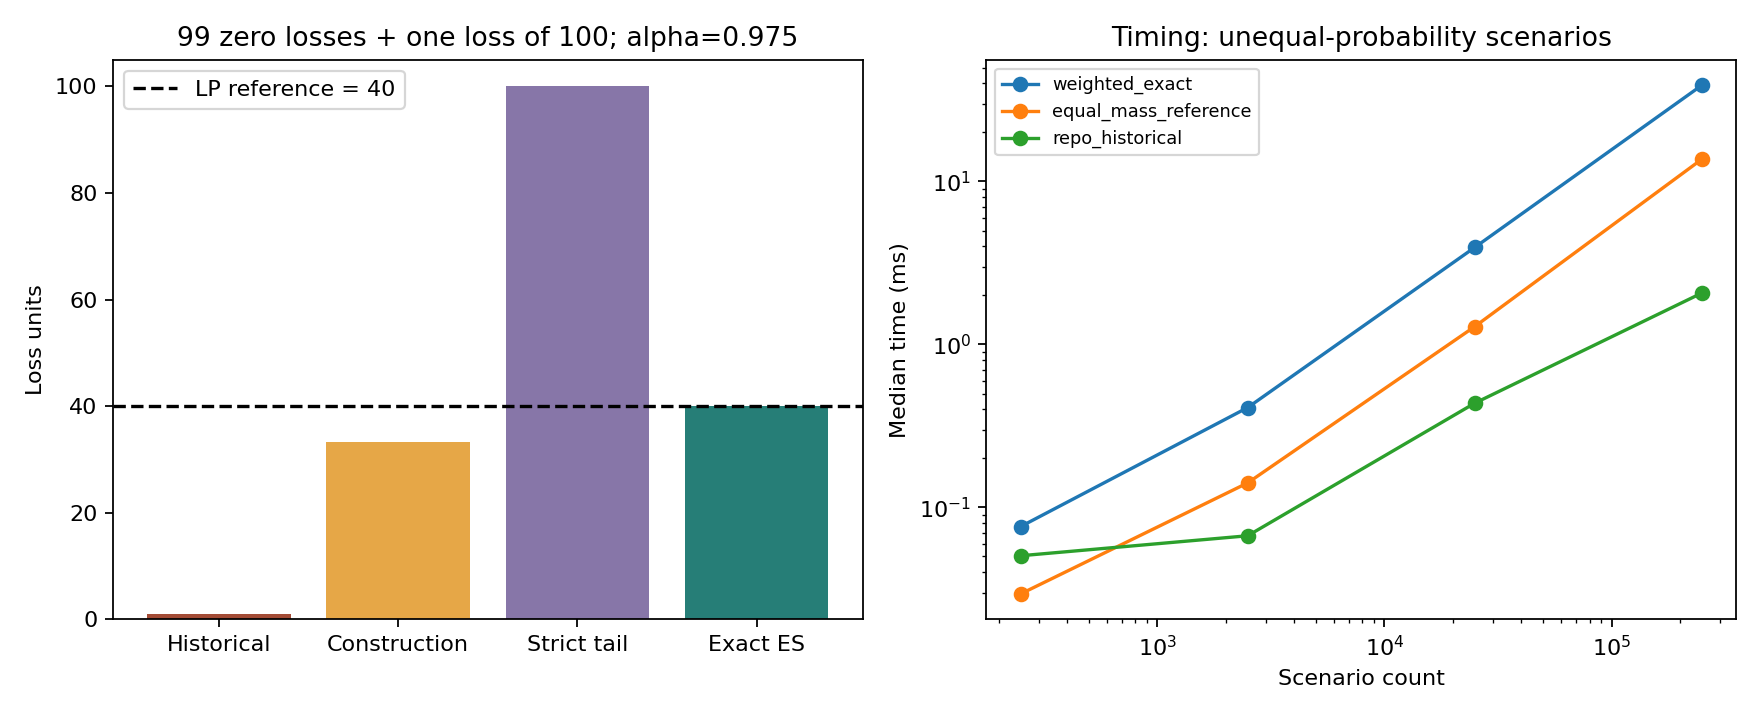

In [3]:
from IPython.display import Image, display
display(Image(filename='results/audit.png'))

## Conclusiones y límites

La diferencia es definicional, no una mejora probada del pronóstico. El método exacto consume más recursos que el promedio por umbral. No estima probabilidades ni incertidumbre de población; no representa capital regulatorio. La cola estricta puede estar vacía. Ver informe.md y referencias.bib. Siguiente paso: migración con pruebas de regresión y contrato común Python/C++.